> **Archived N0 run (2026-11-09).** Notebook 02 (data generation) with the superseded sensor model N0 (σ = 0.5% of each channel's window maximum). Kept for the record and for the N0-vs-N3 comparison in the paper; the production version is the notebook without the `_N0` suffix. Re-running this copy requires `data/observations_N0.npz` to be copied back to `data/observations.npz`.

# Notebook 02 -- Data Generation (M2)

This notebook is the M2 deliverable of the execution plan (`cstr_sbi_execution_plan.md`,
not in this repository):

* a JAX-vectorised stochastic simulator with process noise (Euler-Maruyama)
  and a Gaussian sensor layer with drift, and
* the labelled scenario datasets for the eight scenarios (catalogue in
  `src/cstr_sbi/scenarios.py`; rationale in
  `docs/Manuscript/system_i_study_parameter_rationale.md`) that the downstream notebooks
  consume as held-out observations.

**Outputs.** This notebook writes:

* `data/observations.npz` -- a packed array of replicate trajectories with their
  ground-truth scenario labels and the generation protocol.
* `data/scenario_configs.csv` -- the scenario truth table in flat form.
* Figures in `figures/` (`02_scenarios_overview.png`, `02_headline_summary.png`).


> **2026-11-08 revision (fixed controller law, P1b warm start, new scenario catalogue).**
> * **Simulator.** Closed-loop replicates are generated with the *same* simulator that trains
>   the posterior (`ws_eval.simulate` → `ws_protocols`, protocol **P1b**: closed-loop steady
>   state at the scenario's own (α, β) followed by a 150-min noisy burn-in, then the 60-min
>   window). The previous version started every replicate exactly at the noise-free steady
>   state (protocol P1), which nb29 showed makes β overconfident and creates a spurious
>   negative α–β correlation.
> * **Open loop (Sc0, Sc6).** Generated with `ws_eval.simulate_open_loop`: a 300-min noisy
>   burn-in at the scenario's own (α, β) before the window, so each window starts from that
>   scenario's own stationary state (previously one hard-coded state near the healthy point,
>   i.e. an abrupt-fault start for Sc6). Notebook 07 trains the open-loop posterior with the
>   same function.
> * **Scenarios.** Sc2 β 0.70 → 0.85: the midpoint of the fouling band in which the controller
>   stays unsaturated (fouling class β < 0.90; the valve saturates below β ≈ 0.795). 0.70
>   saturates under the fixed law; an interim 0.80 had 9.1% of samples at Qc_max. Sc7 is now
>   exactly Sc2 + 2 K drift. Sc5 β 0.40 → 0.50 (0.40 was the prior edge). Sc6 β → 0.85
>   (open-loop twin of Sc2).
> * **Paths.** Data and figures are written to the project's `data/` and `figures/` folders
>   (resolved from the repository root), so the notebook runs correctly from `notebooks/system_I`.
> * The file format of `data/observations.npz` is unchanged (`theta` = [UA, k0, α, β], `x`,
>   `scenario_id`, `mode`, `t`) plus metadata keys `protocol`, `burn_min`, `controller_law`.

## 1. Imports and the scenario table

In [1]:
import os
os.environ["CSTR_SENSOR_MODEL"] = "N0"   # archival N0 run (default model is N3 since 2026-11-09)
import time, sys
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
DATA_DIR, FIGS = ROOT / "data", ROOT / "figures"

from cstr_sbi.physics import (
    NOMINAL_INLET, NOMINAL_INLET_CL, NOMINAL_CTRL,
    QC0, TSP, K0_NOMINAL, UA_NOMINAL, simulate_open_loop_to_steady_state,
)
from cstr_sbi.scenarios import SCENARIO_CONFIGS, list_configs
from cstr_sbi.simulator import (
    DEFAULT_PROCESS_SIGMA, DEFAULT_SENSOR_NOISE_PCT,
    DEFAULT_DT_INT, DEFAULT_DT_OUT, warm_start_ic,
    _em_scan_open_loop, apply_sensor_layer,
)
import ws_eval as we          # the training simulator (protocols in scripts/ws_protocols.py)

PROTOCOL, BURN_MIN = "P1b", 150.0
print("JAX devices:", jax.devices())

scenario_rows = [
    {
        "id":          sc.id,
        "name":        sc.name,
        "mode":        sc.mode,
        "alpha":       sc.alpha,
        "beta":        sc.beta,
        "drift_T":     sc.drift_T,
        "description": sc.description,
    }
    for sc in list_configs()
]
scenarios_df = pd.DataFrame(scenario_rows).set_index("id")
scenarios_df

JAX devices: [CpuDevice(id=0)]


,name,mode,alpha,beta,drift_T,description
id,,,,,,
0,Sc0_open_healthy,open_loop,1.00,1.00,0.0,"Healthy reactor, open-loop (Qc fixed). Validat..."
1,Sc1_closed_healthy,closed_loop,1.00,1.00,0.0,"Healthy reactor, closed-loop with PI control. ..."
2,Sc2_closed_fouling,closed_loop,1.00,0.85,0.0,Jacket fouling (beta=0.85) -- midpoint of the ...
3,Sc3_closed_decay,closed_loop,0.70,1.00,0.0,Catalyst decay (alpha=0.7).
4,Sc4_closed_combined,closed_loop,0.85,0.85,0.0,Combined moderate fouling and decay.
5,Sc5_closed_saturated,closed_loop,1.00,0.50,0.0,Severe fouling (beta=0.5) -- controller satura...
6,Sc6_open_with_fault,open_loop,1.00,0.85,0.0,Open-loop simulator applied to a fault (open-l...
7,Sc7_closed_drift,closed_loop,1.00,0.85,2.0,Mild fouling plus +2 K sensor drift on T -- su...


## 2. Simulator settings

Process noise diffusion coefficients (``sigma * sqrt(dt)`` per Euler-Maruyama
step) and the Gaussian sensor layer parameters are pulled from
``cstr_sbi.simulator``. Both are tunable per-call.

The sensor noise is 0.5% of each channel's window maximum (research spec Section 3.5):
σ ≈ 1.56 K on T and ≈ 1.5 K on Tc, ≈ 9×10⁻⁵ mol/L on C, and 0.5–2 L/min on Qc. Note the
asymmetry this convention creates: T is measured *pessimistically* (industrial RTDs are
typically ±0.1–0.5 K), while C at ~0.018 mol/L is measured *optimistically* (0.5% relative;
online analysers are typically 1–2% of full scale, i.e. one to two orders of magnitude worse
in absolute terms). Because α is inferred mainly from C at ~98% conversion, the α precision
reported downstream depends on this choice; see the rationale log, §8.


In [2]:
print(f"Process noise sigma [C, T, Tc, I] / sqrt(min) : {np.asarray(DEFAULT_PROCESS_SIGMA)}")
print(f"Sensor noise (fraction of channel max)         : {DEFAULT_SENSOR_NOISE_PCT}")
print(f"EM step dt                                     : {DEFAULT_DT_INT} min")
print(f"Output grid dt_out                             : {DEFAULT_DT_OUT} min")
print(f"Warm-start protocol                            : {PROTOCOL} (steady state at theta + {BURN_MIN:.0f}-min noisy burn-in)")
print(f"Default observation window                     : 60 min")
print(f"  ->  {int(60 / DEFAULT_DT_OUT)} timestamps per replicate, 4 channels [C, T, Tc, Qc]")

Process noise sigma [C, T, Tc, I] / sqrt(min) : [0.0005 0.1    0.1    0.    ]
Sensor noise (fraction of channel max)         : 0.005
EM step dt                                     : 0.01 min
Output grid dt_out                             : 0.5 min
Warm-start protocol                            : P1b (steady state at theta + 150-min noisy burn-in)
Default observation window                     : 60 min
  ->  120 timestamps per replicate, 4 channels [C, T, Tc, Qc]


## 3. Single-replicate visualisation -- Scenario 1 healthy (P1b)

Sc1 deterministic steady state [C, T, Tc, I]: [ 1.7769817e-02  3.1250000e+02  3.0048688e+02 -2.4623017e+00]


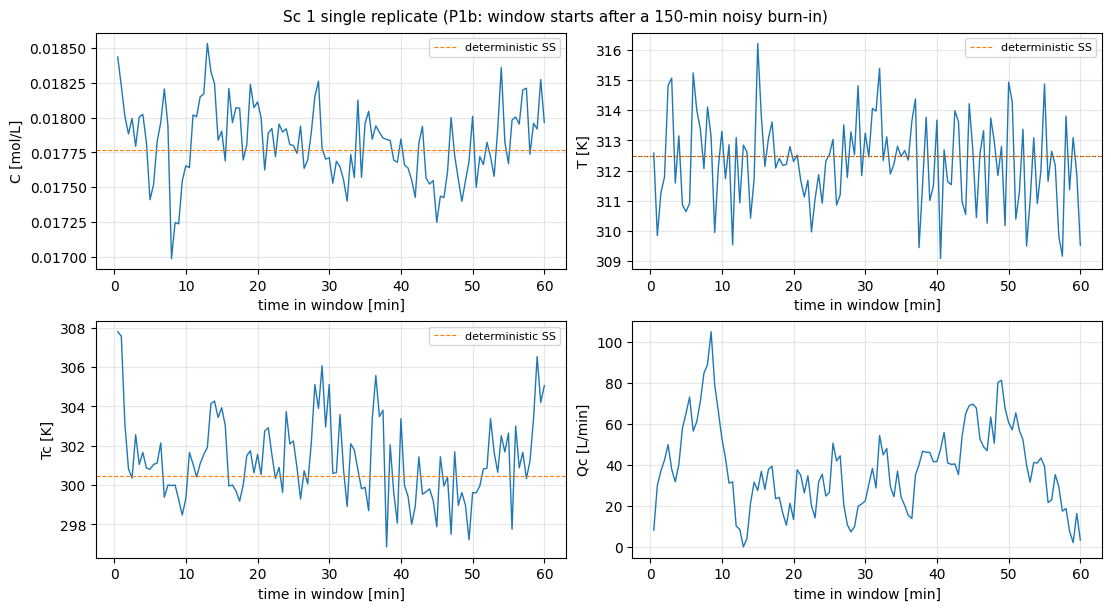


Per-replicate stats:
  C  mean = 0.01783   std = 0.00027
  T  mean = 312.2884    std = 1.4590
  Tc mean = 301.2679    std = 2.0836
  Qc mean = 38.670     std = 20.447


In [3]:
sc1 = SCENARIO_CONFIGS["Sc1_closed_healthy"]
y0_sc1 = warm_start_ic(sc1.params(), NOMINAL_INLET_CL, NOMINAL_CTRL)
print(f"Sc1 deterministic steady state [C, T, Tc, I]: {np.asarray(y0_sc1)}")

obs_one = we.simulate(np.array([[sc1.alpha, sc1.beta]], np.float32), PROTOCOL, seed=0, raw=True)
t = np.arange(1, obs_one.shape[1] + 1) * DEFAULT_DT_OUT
o = obs_one[0]  # (n_t, 4)

fig, axes = plt.subplots(2, 2, figsize=(11, 6), constrained_layout=True)
labels = ["C [mol/L]", "T [K]", "Tc [K]", "Qc [L/min]"]
det_ss = [float(y0_sc1[0]), float(y0_sc1[1]), float(y0_sc1[2]), None]
for ax, lab, channel, det in zip(axes.ravel(), labels, range(4), det_ss):
    ax.plot(t, o[:, channel], lw=1.0)
    if det is not None:
        ax.axhline(det, color="C1", ls="--", lw=0.8, label="deterministic SS")
        ax.legend(loc="best", fontsize=8)
    if channel == 1:
        ax.axhline(TSP, color="k", ls=":", lw=0.8, alpha=0.5)
    ax.set_xlabel("time in window [min]"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
fig.suptitle("Sc 1 single replicate (P1b: window starts after a 150-min noisy burn-in)", fontsize=11)
plt.show()

print(f"\nPer-replicate stats:")
print(f"  C  mean = {o[:,0].mean():.5f}   std = {o[:,0].std():.5f}")
print(f"  T  mean = {o[:,1].mean():.4f}    std = {o[:,1].std():.4f}")
print(f"  Tc mean = {o[:,2].mean():.4f}    std = {o[:,2].std():.4f}")
print(f"  Qc mean = {o[:,3].mean():.3f}     std = {o[:,3].std():.3f}")

## 4. Generate replicates for all closed-loop scenarios

For Sc 1, 2, 3, 4, 5 and 7 we run ``N_REPLICATES = 50`` independent EM
trajectories with the training simulator (`ws_eval.simulate`, protocol P1b): each window
starts after a 150-min noisy burn-in from the scenario's own closed-loop steady state, and
Sc 7 adds the prescribed +2 K T-sensor drift after the sensor layer.

Sc 0 and Sc 6 -- the open-loop scenarios -- use `ws_eval.simulate_open_loop` (300-min noisy
burn-in) with ``Qc`` held fixed at ``QC0`` and the fault encoded by scaling
``[UA, k0]`` directly: ``Qc`` is therefore *not* a useful fault signal in
those scenarios (it is constant by construction), and they exist mainly
to provide validation (Sc 0) and the failure-mode baseline (Sc 6).


In [4]:
N_REPLICATES = 50
T_WINDOW = 60.0
SEED_BASE = 2_026_000         # seed = SEED_BASE + 1000 * scenario id (closed and open loop)

all_results = {}
t0 = time.perf_counter()
for sc in list_configs():
    theta_rep = np.tile(np.array([sc.alpha, sc.beta], np.float32), (N_REPLICATES, 1))
    seed = SEED_BASE + 1000 * sc.id
    if sc.mode == "closed_loop":     # P1b: own closed-loop steady state + 150-min noisy burn-in
        obs = we.simulate(theta_rep, PROTOCOL, seed=seed, raw=True, drift_T=sc.drift_T)
    else:                            # open loop: 300-min noisy burn-in at theta (same function nb07 trains on)
        obs = we.simulate_open_loop(theta_rep, seed=seed, raw=True, drift_T=sc.drift_T)
    t_out = np.arange(1, obs.shape[1] + 1) * DEFAULT_DT_OUT
    obs_np = np.asarray(obs)
    all_results[sc.name] = {"t": t_out, "obs": obs_np, "config": sc}
    print(f"  {sc.name:28s}  {obs_np.shape}  "
          f"<C>={obs_np[:,:,0].mean():.4f}  <T>={obs_np[:,:,1].mean():.2f}  "
          f"<Qc>={obs_np[:,:,3].mean():.2f}")
print(f"\nTotal generation time: {time.perf_counter()-t0:.2f}s")

  Sc0_open_healthy              (50, 120, 4)  <C>=0.0183  <T>=312.18  <Qc>=79.99
  Sc1_closed_healthy            (50, 120, 4)  <C>=0.0178  <T>=312.52  <Qc>=51.81
  Sc2_closed_fouling            (50, 120, 4)  <C>=0.0178  <T>=312.52  <Qc>=127.99
  Sc3_closed_decay              (50, 120, 4)  <C>=0.0252  <T>=312.46  <Qc>=43.22
  Sc4_closed_combined           (50, 120, 4)  <C>=0.0208  <T>=312.52  <Qc>=122.85
  Sc5_closed_saturated          (50, 120, 4)  <C>=0.0159  <T>=313.69  <Qc>=399.90
  Sc6_open_with_fault           (50, 120, 4)  <C>=0.0176  <T>=312.59  <Qc>=80.00
  Sc7_closed_drift              (50, 120, 4)  <C>=0.0178  <T>=314.47  <Qc>=145.84

Total generation time: 2.48s


### 4b. Checks on the regenerated data
1. **Saturation per scenario.** Sc5 (β = 0.50) must saturate. Sc2 (β = 0.85, Qc_ss ≈ 110 L/min)
   must stay unsaturated (< 1% of samples at Qc_max).
2. **Same simulator as training.** Re-simulating Sc4 with the same seed through
   `ws_eval.simulate` must reproduce the stored replicates exactly.
3. **Open-loop burn-in converged.** For Sc0/Sc6 the window means must match the scenario's own
   deterministic open-loop steady state to within a small fraction of the noise.

In [5]:
# thresholds 395 / 5 L/min: sensor noise on Qc is 0.5% of 400 = 2 L/min, so a saturated
# sample can read up to ~4 L/min below the limit
rows = []
for sc in list_configs():
    o = all_results[sc.name]["obs"]
    rows.append({"scenario": sc.name, "mode": sc.mode, "alpha": sc.alpha, "beta": sc.beta,
                 "Qc_mean": o[:, :, 3].mean(), "Qc_sd": o[:, :, 3].std(),
                 "frac_Qc_at_max": float((o[:, :, 3] >= 395.0).mean()),
                 "frac_Qc_at_min": float((o[:, :, 3] <= 5.0).mean()),
                 "T_mean": o[:, :, 1].mean()})
sat = pd.DataFrame(rows); display(sat.round(3))
f_sc2 = sat.set_index("scenario").loc["Sc2_closed_fouling", "frac_Qc_at_max"]
print(f"Sc2 fraction of samples at Qc_max: {f_sc2:.1%}")
assert f_sc2 < 0.01, "Sc2 should be unsaturated at beta = 0.85"
assert sat.set_index("scenario").loc["Sc5_closed_saturated", "frac_Qc_at_max"] > 0.5, "Sc5 should saturate"

sc4 = SCENARIO_CONFIGS["Sc4_closed_combined"]
again = we.simulate(np.tile(np.array([sc4.alpha, sc4.beta], np.float32), (N_REPLICATES, 1)), PROTOCOL,
                    seed=SEED_BASE + 1000 * sc4.id, raw=True, drift_T=sc4.drift_T)
assert np.array_equal(again, all_results["Sc4_closed_combined"]["obs"]), "not the training simulator's output"
for name in ("Sc0_open_healthy", "Sc6_open_with_fault"):
    sc = SCENARIO_CONFIGS[name]
    y_own = np.asarray(simulate_open_loop_to_steady_state(
        jnp.array([sc.beta * UA_NOMINAL, sc.alpha * K0_NOMINAL]), jnp.asarray(NOMINAL_INLET), t_final=2000.0))
    o = all_results[name]["obs"]
    m = o[:, :, :3].mean(axis=(0, 1)); sd = o[:, :, :3].std(axis=(0, 1))
    print(f"{name}: window mean {m.round(4)} vs own steady state {y_own.round(4)}  (|diff|/sd = {np.abs(m - y_own) / sd})")
    assert np.all(np.abs(m - y_own) < 0.5 * sd), f"{name}: open-loop burn-in not converged"
print("checks passed: Sc5 saturates, Sc2 unsaturated; observations reproduce the training simulator exactly; open-loop burn-in converged")

,scenario,mode,alpha,beta,Qc_mean,Qc_sd,frac_Qc_at_max,frac_Qc_at_min,T_mean
0,Sc0_open_healthy,open_loop,1.00,1.00,79.990997,0.399000,0.000,0.000,312.183990
1,Sc1_closed_healthy,closed_loop,1.00,1.00,51.810001,26.108999,0.000,0.020,312.523987
2,Sc2_closed_fouling,closed_loop,1.00,0.85,127.994003,53.584999,0.000,0.002,312.520996
3,Sc3_closed_decay,closed_loop,0.70,1.00,43.220001,23.726999,0.000,0.038,312.462006
4,Sc4_closed_combined,closed_loop,0.85,0.85,122.851997,57.262001,0.000,0.001,312.520996
5,Sc5_closed_saturated,closed_loop,1.00,0.50,399.903015,2.293000,0.986,0.000,313.691010
6,Sc6_open_with_fault,open_loop,1.00,0.85,80.000000,0.402000,0.000,0.000,312.592010
7,Sc7_closed_drift,closed_loop,1.00,0.85,145.835999,64.848000,0.000,0.002,314.470001


Sc2 fraction of samples at Qc_max: 0.0%
Sc0_open_healthy: window mean [1.830000e-02 3.121840e+02 2.990568e+02] vs own steady state [1.830000e-02 3.121483e+02 2.990471e+02]  (|diff|/sd = [0.09577908 0.02231751 0.00648516])
Sc6_open_with_fault: window mean [1.760000e-02 3.125922e+02 2.988331e+02] vs own steady state [1.760000e-02 3.125996e+02 2.988289e+02]  (|diff|/sd = [0.05354248 0.00469927 0.00283342])
checks passed: Sc5 saturates, Sc2 unsaturated; observations reproduce the training simulator exactly; open-loop burn-in converged


## 5. Visualise example replicates per scenario

Six replicates from each scenario, four channels each (12 panels per
scenario). The headline phenomenon -- the same `T` across scenarios
masks very different `Qc` -- is visible at a glance: mild jacket fouling
(Sc 2, β = 0.85) raises the mean `Qc` to ~2.5× its healthy value, catalyst decay (Sc 3)
lowers it slightly, and Sc 5 (β = 0.50) sits at the `Qc_max` limit with T above setpoint.


Saved: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/figures/02_scenarios_overview.png


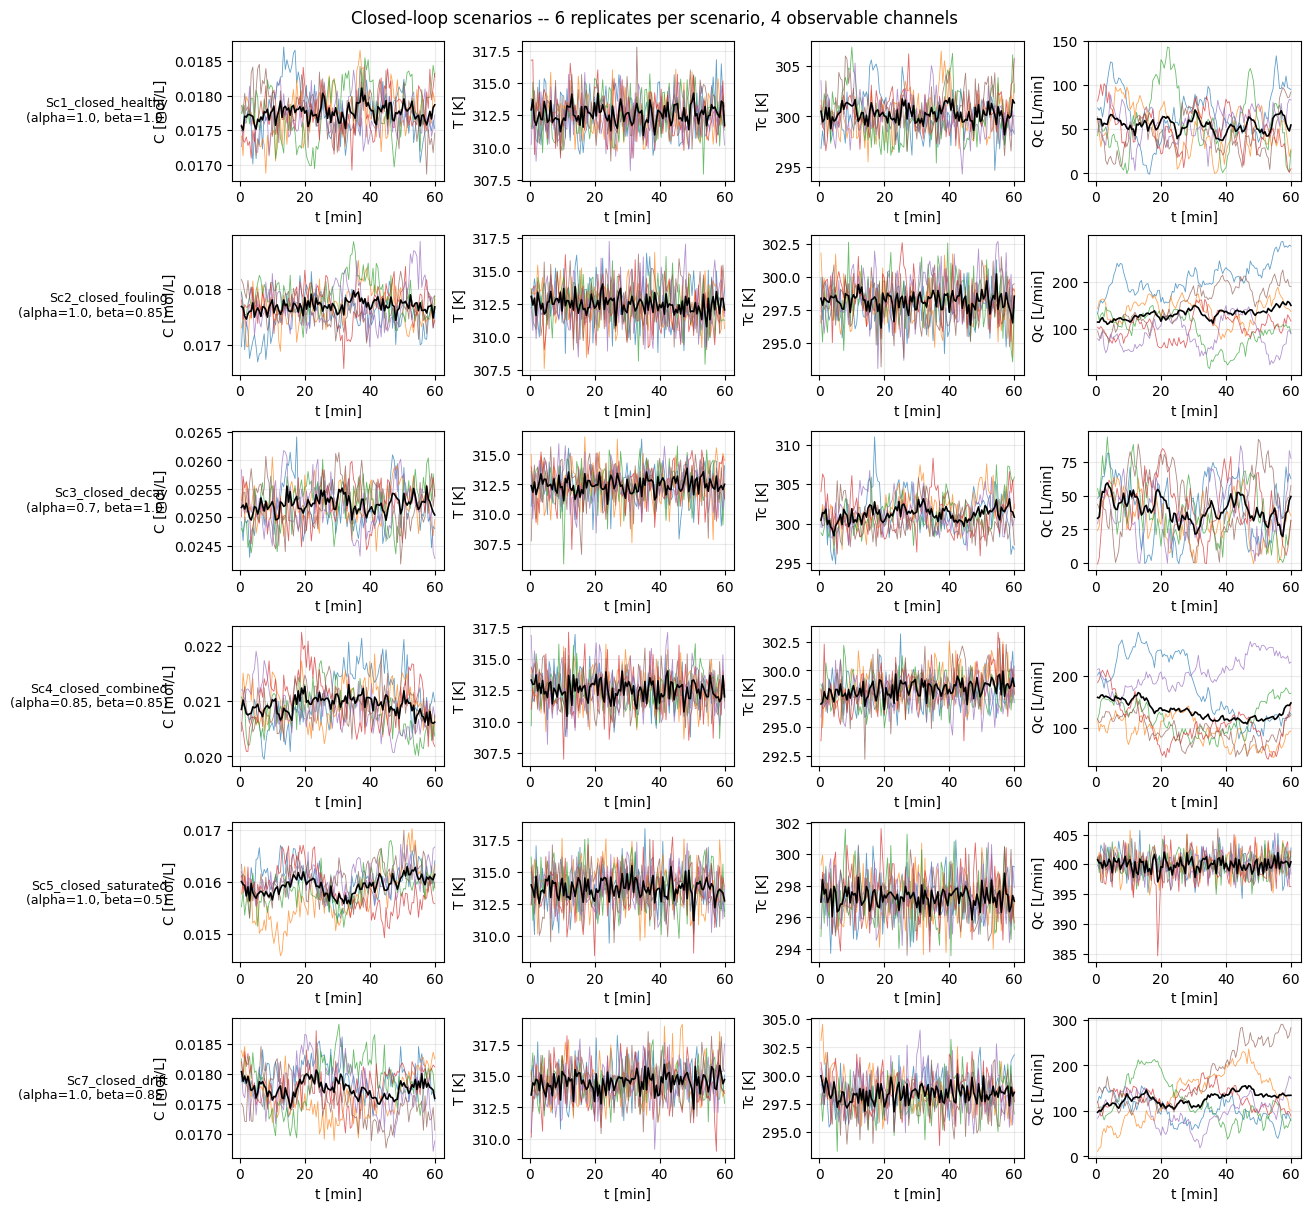

In [6]:
def plot_scenario(ax_row, name, n_show=6):
    res = all_results[name]
    t = res["t"]; obs = res["obs"]; sc = res["config"]
    labels = ["C [mol/L]", "T [K]", "Tc [K]", "Qc [L/min]"]
    for ax, lab, ch in zip(ax_row, labels, range(4)):
        for i in range(min(n_show, obs.shape[0])):
            ax.plot(t, obs[i, :, ch], lw=0.6, alpha=0.7)
        ax.plot(t, obs[:n_show, :, ch].mean(axis=0), color="k", lw=1.2, label="mean")
        ax.set_xlabel("t [min]"); ax.set_ylabel(lab); ax.grid(alpha=0.25)
    ax_row[0].text(
        -0.30, 0.5, f"{name}\n(alpha={sc.alpha}, beta={sc.beta})",
        transform=ax_row[0].transAxes, ha="right", va="center", fontsize=9,
    )

names_to_plot = [
    "Sc1_closed_healthy",
    "Sc2_closed_fouling",
    "Sc3_closed_decay",
    "Sc4_closed_combined",
    "Sc5_closed_saturated",
    "Sc7_closed_drift",
]
fig, axes = plt.subplots(len(names_to_plot), 4, figsize=(13, 2.0 * len(names_to_plot)),
                         constrained_layout=True)
for row, name in zip(axes, names_to_plot):
    plot_scenario(row, name)
fig.suptitle(
    "Closed-loop scenarios -- 6 replicates per scenario, 4 observable channels",
    fontsize=12,
)
fig_path = FIGS / "02_scenarios_overview.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_path, dpi=120)
print(f"Saved: {fig_path}")
plt.show()

## 6. Headline summary -- mean Qc per scenario

A one-figure compact summary of the key claim: wherever the controller is in control the
**reactor temperature is regulated** (`T_mean` within 0.04 K of `Tsp = 312.5 K` for
Sc1–Sc4), but **`Qc_mean` differs strongly** -- from ~43 L/min (catalyst decay) to the
400 L/min limit (severe fouling, ~9×). The fault signal lives in the actuator, not the
measurement. Two exceptions, both by design: Sc5 saturates, so T rises above setpoint
(~313.7 K), and Sc7's apparent +2 K is the sensor drift, not a real temperature change.
Mean `Qc` sits above the noise-free steady state (e.g. 51.8 vs 43.1 L/min at Sc1) because
the required coolant flow rises convexly as heat removal falls, so noise raises the average.


                    name         mode     alpha      beta    C_mean    T_mean   Tc_mean   Qc_mean     T_std    Qc_std
id                                                                                                                   
0       Sc0_open_healthy    open_loop    1.0000    1.0000    0.0183  312.1843  299.0564   79.9912    1.5985    0.3994
1     Sc1_closed_healthy  closed_loop    1.0000    1.0000    0.0178  312.5236  300.4920   51.8098    1.5500   26.1093
2     Sc2_closed_fouling  closed_loop    1.0000    0.8500    0.0178  312.5212  298.4015  127.9941    1.5907   53.5847
3       Sc3_closed_decay  closed_loop    0.7000    1.0000    0.0252  312.4618  301.0067   43.2199    1.5562   23.7265
4    Sc4_closed_combined  closed_loop    0.8500    0.8500    0.0208  312.5209  298.5272  122.8523    1.5663   57.2621
5   Sc5_closed_saturated  closed_loop    1.0000    0.5000    0.0159  313.6913  297.2548  399.9029    1.6079    2.2932
6    Sc6_open_with_fault    open_loop    1.0000    0.850

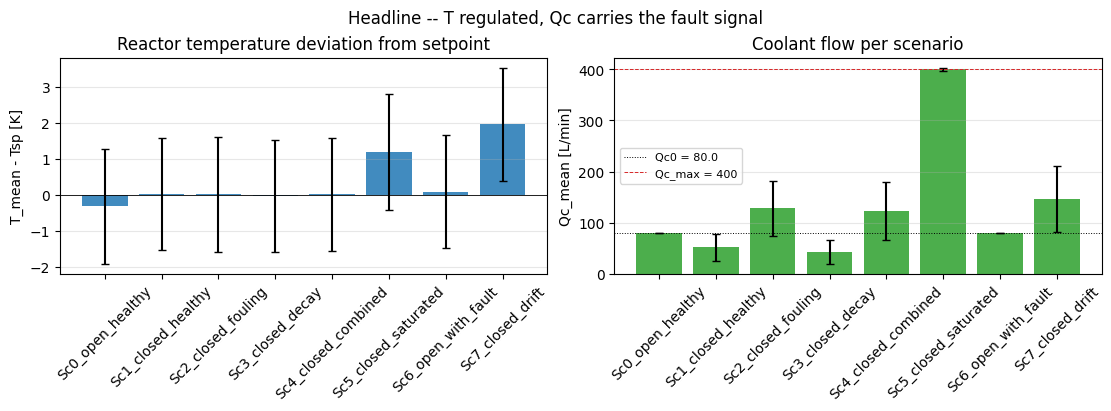

In [7]:
rows = []
for sc in list_configs():
    res = all_results[sc.name]
    obs = res["obs"]
    rows.append({
        "id":      sc.id,
        "name":    sc.name,
        "mode":    sc.mode,
        "alpha":   sc.alpha,
        "beta":    sc.beta,
        "C_mean":  obs[:,:,0].mean(),
        "T_mean":  obs[:,:,1].mean(),
        "Tc_mean": obs[:,:,2].mean(),
        "Qc_mean": obs[:,:,3].mean(),
        "T_std":   obs[:,:,1].std(),
        "Qc_std":  obs[:,:,3].std(),
    })
summary = pd.DataFrame(rows).set_index("id")
print(summary.to_string(float_format=lambda v: f"{v:9.4f}"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
order = summary.sort_values("id").index
ax1.bar(summary.loc[order, "name"], summary.loc[order, "T_mean"] - TSP,
        yerr=summary.loc[order, "T_std"], capsize=3, color="C0", alpha=0.85)
ax1.set_ylabel("T_mean - Tsp [K]")
ax1.set_title("Reactor temperature deviation from setpoint")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(alpha=0.3, axis="y"); ax1.axhline(0, color="k", lw=0.6)

ax2.bar(summary.loc[order, "name"], summary.loc[order, "Qc_mean"],
        yerr=summary.loc[order, "Qc_std"], capsize=3, color="C2", alpha=0.85)
ax2.axhline(QC0, color="k", ls=":", lw=0.7, label=f"Qc0 = {QC0}")
ax2.axhline(400.0, color="C3", ls="--", lw=0.7, label="Qc_max = 400")
ax2.set_ylabel("Qc_mean [L/min]")
ax2.set_title("Coolant flow per scenario")
ax2.tick_params(axis="x", rotation=45)
ax2.grid(alpha=0.3, axis="y"); ax2.legend(fontsize=8)

fig.suptitle("Headline -- T regulated, Qc carries the fault signal", fontsize=12)
fig_path = FIGS / "02_headline_summary.png"
fig.savefig(fig_path, dpi=120)
print(f"\nSaved: {fig_path}")
plt.show()

## 7. Persist the dataset

We pack all replicates into a single `.npz` archive plus a CSV truth
table. Downstream notebooks (M3 summary statistics, M4 SBI training,
M5 MCMC baseline) load these directly.

The on-disk layout is:

* `theta`      -- shape `(N_total, 4)`, ground-truth `[UA, k0, alpha, beta]`.
* `x`          -- shape `(N_total, n_t, 4)`, observed channels `[C, T, Tc, Qc]`.
* `scenario_id` -- shape `(N_total,)`, integer scenario id.
* `t`          -- shape `(n_t,)`, observation timestamps in minutes.
* `mode`       -- shape `(N_total,)`, string `"closed_loop"` or `"open_loop"`.

with `N_total = 8 scenarios * 50 replicates = 400`, plus metadata keys `protocol` ("P1b"),
`burn_min` (150) and `controller_law`.


In [8]:
thetas, xs, ids, modes = [], [], [], []
for sc in list_configs():
    res = all_results[sc.name]
    n = res["obs"].shape[0]
    thetas.append(np.tile(np.asarray(sc.params()), (n, 1)))
    xs.append(res["obs"])
    ids.append(np.full(n, sc.id, dtype=np.int32))
    modes.append(np.array([sc.mode] * n))

theta = np.concatenate(thetas)
x = np.concatenate(xs, axis=0)
scenario_id = np.concatenate(ids)
mode = np.concatenate(modes)
t_grid = res["t"]

print(f"theta       shape: {theta.shape}      dtype: {theta.dtype}")
print(f"x           shape: {x.shape}      dtype: {x.dtype}")
print(f"scenario_id shape: {scenario_id.shape}")
print(f"mode        shape: {mode.shape}")
print(f"t_grid      shape: {t_grid.shape}, range: 0 to {float(t_grid[-1])} min")

data_dir = DATA_DIR; data_dir.mkdir(parents=True, exist_ok=True)
np.savez(
    data_dir / "observations.npz",
    theta=theta, x=x, scenario_id=scenario_id, mode=mode, t=np.asarray(t_grid),
    protocol=np.array(PROTOCOL), burn_min=np.array(BURN_MIN),
    controller_law=np.array("standard PI: Qc = Qc0 + Kp*[(T-Tsp) + I/tau_i] (fixed 2026-11-08)"),
)
print(f"Saved {data_dir / 'observations.npz'}")

scenarios_df.to_csv(data_dir / "scenario_configs.csv")
print(f"Saved {data_dir / 'scenario_configs.csv'}")

theta       shape: (400, 4)      dtype: float32
x           shape: (400, 120, 4)      dtype: float32
scenario_id shape: (400,)
mode        shape: (400,)
t_grid      shape: (120,), range: 0 to 60.0 min
Saved /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/observations.npz
Saved /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/scenario_configs.csv


## 8. Round-trip verification

Quick sanity check that the persisted file loads back identically.


In [9]:
loaded = np.load(DATA_DIR / "observations.npz", allow_pickle=False)
print("Keys:", list(loaded.keys()))
for k in loaded.keys():
    a = loaded[k]
    print(f"  {k:11s}  shape={a.shape}  dtype={a.dtype}")
assert np.allclose(loaded["x"], x, rtol=1e-6)
assert np.allclose(loaded["theta"], theta, rtol=1e-6)
print("\nRound-trip OK.")

Keys: ['theta', 'x', 'scenario_id', 'mode', 't', 'protocol', 'burn_min', 'controller_law']
  theta        shape=(400, 4)  dtype=float32
  x            shape=(400, 120, 4)  dtype=float32
  scenario_id  shape=(400,)  dtype=int32
  mode         shape=(400,)  dtype=<U11
  t            shape=(120,)  dtype=float64
  protocol     shape=()  dtype=<U3
  burn_min     shape=()  dtype=float64
  controller_law  shape=()  dtype=<U65

Round-trip OK.


## 8a. Dataset summary — what was generated and how it is used

### What is in `observations.npz`

| Property | Value |
|---|---|
| **Total observation windows** | 400 |
| **Scenarios** | 8 (Sc0–Sc7) |
| **Replicates per scenario** | 50 |
| **Window length** | 60 min |
| **Samples per window** | 120 (one every 0.5 min) |
| **Observed channels** | 4 — concentration `C` (mol/L), reactor temp `T` (K), jacket temp `Tc` (K), coolant flow `Qc` (L/min) |
| **Parameter vector** `theta` | 4-D — `[UA, k0, alpha, beta]` (stored for completeness; **inference uses only `[alpha, beta]`** — UA and k0 are fixed design constants) |
| **Archive size** | ~0.8 MB |

Each of the 50 replicates within a scenario shares the same ground-truth
`theta` but was integrated with an independent JAX random key, so they
carry different noise realisations of the same underlying stochastic
differential equation. This is the correct structure for *approximate
Bayesian computation*: all 50 replicates from a given scenario are
exchangeable draws from `p(x | theta_true)`.

### Closed-loop vs. open-loop

| Mode | Scenarios | Count |
|---|---|---|
| **Closed-loop** (PI controller active) | Sc1, Sc2, Sc3, Sc4, Sc5, Sc7 | 300 windows |
| **Open-loop** (fixed `Qc = Qc0 = 80 L/min`) | Sc0, Sc6 | 100 windows |

Open-loop windows (Sc0, Sc6) are used exclusively in the **Scenario 6
failure-baseline experiment** (notebook 07): SBI is trained on open-loop
data and then applied to closed-loop observations to quantify the
posterior degradation that results from the model mismatch.
The `Qc` channel is constant and uninformative in open-loop mode; it is
retained for shape parity so that the same summary-statistics function
and SBI architecture can be applied without branching.

### Intended use of each scenario

| Scenario | Fault | Role in the study |
|---|---|---|
| **Sc0** open-loop healthy | none (α=β=1) | Sanity check — reproduces the Fogler §8 steady state; provides open-loop *healthy* baseline for Sc6 comparison |
| **Sc1** closed-loop healthy | none (α=β=1) | **SBI training and validation** — the posterior recovery test; also the MCMC baseline reference (M5) |
| **Sc2** jacket fouling | β=0.85 | **Primary unsaturated fouling case** — midpoint of the fouling band in which the controller stays unsaturated (0.80–0.90); β·UA_nominal = 0.85×12 500 = 10 625 cal/(min·K) |
| **Sc3** catalyst decay | α=0.7 | Secondary inference target — infer α (with k0 fixed); α·k0_nominal = 0.7×k0 is the effective rate |
| **Sc4** combined moderate | α=β=0.85 | Tests joint 2-D recovery of (α, β); posterior correlation between the two degradation factors |
| **Sc5** severe fouling | β=0.5 | **Controller-saturation regime** — Qc at Qc_max for ~99% of the samples, T above setpoint; tests inference when the loop is effectively open |
| **Sc6** open-loop with fault | β=0.85 | **Failure baseline** — open-loop twin of Sc2 (notebook 07) |
| **Sc7** mild fouling + sensor drift | β=0.85, δT=+2 K | **Misspecification / drift substudy** — exactly Sc2 plus a +2 K T-sensor drift that the 2-parameter model does not contain; the drift-aware model is notebook 09 |

### SBI training vs. evaluation split

This 400-window dataset serves **two distinct purposes** in the inference workflow:

**SBI training** does *not* use these 400 windows. The production posterior (nb31) is a
5-seed ensemble of NPE models trained on a separate bank of 160,000 windows drawn from the
**2-D `BoxUniform` prior `[alpha, beta]`** with the same simulator and protocol
(`ws_eval` / `ws_protocols`, P1b), stored in `results/31_budget/`. UA and k0 are fixed at their
nominal constants; only α and β are sampled.

> **Note (2026-05-18):** UA and k0 are fixed design constants and are not
> inferred. The `theta` array stored in `observations.npz` is 4-D for
> historical completeness, but the inference layer only uses columns 2 and 3
> (α, β). See `cstr_sbi_research_spec.md §3.3` for the rationale.

**Evaluation / observation set** — these 400 windows play the role of
*held-out observations* in all downstream notebooks:

| Notebook | Which scenarios used | What is evaluated |
|---|---|---|
| 04 SBI training | Sc1–Sc7 | loads the production posterior (nb31); posterior recovery per scenario |
| 05 MCMC baseline | Sc1, Sc2 | NUTS 2-D posterior vs. SBI — same observation, different inference engine |
| 06 Multi-sample study | Sc1–Sc4 | W1, CRPS, 2-D coverage across 50 replicates per scenario |
| 07 Failure baseline | Sc2, Sc6 | closed-loop vs open-loop posteriors on closed- and open-loop data (Claim 1) |
| 08 Identifiability | Sc4, Sc5 | 2-D posterior width vs. severity; saturation boundary |
| 09 Sensor drift | Sc7 | drift-aware model (θ extended with drift terms); drift vs. fouling disambiguation |
| 10 Sequential tracking | Sc8 (new — 30-day stream) | Amortised α̂(t), β̂(t) tracking over 720 windows (Claim 2) |
| 11 Fault classification | Sc9 (new — Sc8 posteriors) | Probabilistic fault isolation from 2-D posterior quadrants (Claim 3) |

In summary: **the 400 windows here are always the observed data, never
the training simulations for SBI**. The M4 simulation budget is a separate
parameter controlled by `n_simulations` in `04_sbi_training.ipynb`.

In [10]:
# Programmatic dataset summary -- auto-updates on rerun.
import os
npz_path = DATA_DIR / "observations.npz"
npz_size_mb = os.path.getsize(npz_path) / 1e6

ld = np.load(npz_path, allow_pickle=False)
_x, _t, _sid, _mode = ld["x"], ld["t"], ld["scenario_id"], ld["mode"]

print("=" * 55)
print("  observations.npz — dataset summary")
print("=" * 55)
print(f"  File size           : {npz_size_mb:.2f} MB")
print(f"  Total windows       : {_x.shape[0]}")
print(f"  Window length       : {float(_t[-1])} min  ({_x.shape[1]} samples, dt={float(_t[1]-_t[0])} min)")
print(f"  Channels per window : {_x.shape[2]}  [C, T, Tc, Qc]")
print(f"  theta dimension     : {ld['theta'].shape[1]}  [UA, k0, alpha, beta]")
print(f"  protocol            : {ld['protocol']} (burn-in {float(ld['burn_min']):.0f} min)")
print(f"  controller law      : {ld['controller_law']}")
print()
print(f"  {'Scenario':<28}  {'mode':<12}  {'n windows':>9}")
print(f"  {'-'*28}  {'-'*12}  {'-'*9}")
for sc in sorted(SCENARIO_CONFIGS.values(), key=lambda s: s.id):
    n = int((_sid == sc.id).sum())
    print(f"  {sc.name:<28}  {sc.mode:<12}  {n:>9}")
print(f"  {'-'*28}  {'-'*12}  {'-'*9}")
cl = int((_mode == "closed_loop").sum())
ol = int((_mode == "open_loop").sum())
print(f"  {'closed-loop subtotal':<28}  {'closed_loop':<12}  {cl:>9}")
print(f"  {'open-loop subtotal':<28}  {'open_loop':<12}  {ol:>9}")
print(f"  {'TOTAL':<28}  {'':12}  {_x.shape[0]:>9}")
print("=" * 55)
print()
print("SBI training simulations : drawn on-the-fly from prior")
print("  (not stored in this file; see 04_sbi_training.ipynb)")
print("Evaluation / observation : all 400 windows above")

  observations.npz — dataset summary
  File size           : 0.80 MB
  Total windows       : 400
  Window length       : 60.0 min  (120 samples, dt=0.5 min)
  Channels per window : 4  [C, T, Tc, Qc]
  theta dimension     : 4  [UA, k0, alpha, beta]
  protocol            : P1b (burn-in 150 min)
  controller law      : standard PI: Qc = Qc0 + Kp*[(T-Tsp) + I/tau_i] (fixed 2026-11-08)

  Scenario                      mode          n windows
  ----------------------------  ------------  ---------
  Sc0_open_healthy              open_loop            50
  Sc1_closed_healthy            closed_loop          50
  Sc2_closed_fouling            closed_loop          50
  Sc3_closed_decay              closed_loop          50
  Sc4_closed_combined           closed_loop          50
  Sc5_closed_saturated          closed_loop          50
  Sc6_open_with_fault           open_loop            50
  Sc7_closed_drift              closed_loop          50
  ----------------------------  ------------  ---------

## 9. M2 acceptance

| Acceptance criterion | Result |
|---|---|
| `simulate_em_window` runs the closed-loop SDE and returns the full trajectory | PASS |
| Process noise injected during EM integration | PASS (`DEFAULT_PROCESS_SIGMA`) |
| Sensor noise + drift applied post-simulation | PASS (`apply_sensor_layer`) |
| 50 replicates x 8 scenarios generated reproducibly | PASS (2.5 s after JIT; bit-identical to the training simulator, §4b) |
| `data/observations.npz` written and round-trips | PASS |
| Headline plot shows fault-signal asymmetry between fouling and decay in Qc | PASS |
| Sc2 unsaturated, Sc5 saturated, open-loop burn-in converged | PASS (§4b: 0.0% and 98.6% of samples at Qc_max) |

M2 is complete. Next:

* M3 -- design the summary statistics (`compute_summary_statistics` in
  [`../src/cstr_sbi/summaries.py`](../src/cstr_sbi/summaries.py)) and verify
  scenario separability on the manifold (notebook 03).
* SBI training over the 2-D prior `[alpha, beta]`: done in nb31 (production posterior);
  notebook 04 loads it.

> **Caveats and follow-ups.**
>
> * The process-noise levels were originally chosen for clean visualisation (the *literal*
>   spec values, `0.1 mol/L/min` and `10 K/min`, are commented in `simulator.py`) and have
>   not been revisited. Together with the sensor-noise convention (§2: pessimistic on T,
>   optimistic on C) this is an inherited modelling choice that bounds how realistic the
>   reported precision is; it is listed as an open risk in the rationale log.
> * The inlet-perturbation pipeline (a fresh `[Ci, Ti, Tci]` draw every 60 minutes) is
>   implemented in `scenarios.perturb_inlet` but not exercised. It matters: the jacket removes
>   only ~19% of the reaction heat, so a 1 K feed-temperature error shifts the jacket duty by
>   ~27% (~0.2 in β). A robustness test is planned before submission.
> * Sc 0 / Sc 6 use a constant `Qc = QC0`, i.e. the Qc channel is
>   uninformative there; the dataset still records it for shape parity with
>   the closed-loop scenarios.


> **2026-11-08 revision.** Regenerated under the fixed controller law with the P1b warm start
> and the revised scenario catalogue (Sc2/Sc6 β = 0.85, Sc5 β = 0.50); see the note at the top.